<a href="https://colab.research.google.com/github/Juanse541/curso-introduccion-programacion-cientifica/blob/main/proyecto-integrador-pc-grupo-4/notebooks/analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

15/11/2026

**Proyecto de final: Incidentes de Ciberseguridad en Colombia (2023 - 2025)**

Wilmar Quiros Usuga

Juan Sebastián Gómez V.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/ciberseguridad_2023_2025.csv')
ciberseguridad = df
print(ciberseguridad.shape) #Totales filas y columnas
display(df.head()) # Mustra la tabla

(1850, 21)


,id_incidente,fecha_deteccion,anio,departamento,sector,tamano_empresa,num_empleados,presupuesto_ti_pct,tiene_mfa,capacitacion_ultimo_anio,...,tipo_ataque,vector_entrada,severidad,horas_deteccion,horas_contencion,equipos_afectados,registros_expuestos,perdida_estimada_millones_cop,pago_rescate_millones_cop,notificado_a_autoridad
0,CIB-0001,2023-01-01,2023,Antioquia,Educación,Pequeña,17,NaN,No,No,...,Malware,Correo electrónico,Baja,82.9,15.4,1,0.0,31.9,NaN,No
1,CIB-0002,2023-01-01,2023,Bogotá D.C.,Comercio,Mediana,57,4.3,Sí,No,...,Phishing,Correo electrónico,Baja,41.4,11.8,1,NaN,NaN,NaN,Sí
2,CIB-0003,2023-01-03,2023,Atlántico,Comercio,Pequeña,16,3.4,Sí,Sí,...,Ransomware,Vulnerabilidad sin parche,Crítica,374.1,NaN,10,NaN,120.2,65.3,Sí
3,CIB-0004,2023-01-04,2023,Bogotá D.C.,Educación,Mediana,63,3.9,No,NaN,...,Malware,Correo electrónico,Media,12.2,13.3,7,NaN,417.6,NaN,Sí
4,CIB-0005,2023-01-04,2023,Risaralda,Gobierno,Pequeña,23,3.1,No,Sí,...,Phishing,Mensajería,Baja,13.9,9.9,2,NaN,15.8,NaN,Sí


In [ ]:
print(df.info()) # Características principales de la ciberseguridad


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1850 entries, 0 to 1849
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_incidente                   1850 non-null   object 
 1   fecha_deteccion                1850 non-null   object 
 2   anio                           1850 non-null   int64  
 3   departamento                   1850 non-null   object 
 4   sector                         1850 non-null   object 
 5   tamano_empresa                 1850 non-null   object 
 6   num_empleados                  1850 non-null   int64  
 7   presupuesto_ti_pct             1579 non-null   float64
 8   tiene_mfa                      1850 non-null   object 
 9   capacitacion_ultimo_anio       1765 non-null   object 
 10  tiene_soc                      1850 non-null   object 
 11  tipo_ataque                    1850 non-null   object 
 12  vector_entrada                 1850 non-null   o

In [ ]:
faltante = pd.DataFrame({
    "nulos": df.isna().sum(), #identificar los datos que están vacíos o faltantes en una tabla
    "porcentaje": (df.isna().mean() * 100).round(2) #promedio y (.) dos decimales
})


faltante_filtrado = faltante[faltante['nulos'] > 0].sort_values("porcentaje", ascending=False) # Filtro y desordenado
display(faltante_filtrado)

print("\nRescatres reportados por tipos de ataque: ") # Muestra titulo, recuperar información según el tipo de ataque informático.

resumen_ataques = df.groupby("tipo_ataque")["pago_rescate_millones_cop"].agg(["size", "count"]).rename(columns={"size": "Total incidentes", "count": "Rescates pagados"})
display(resumen_ataques) # .gruopby = Agrupar información, .agg y .rename son resumir datos renombrar

q1 = df["horas_deteccion"].quantile(0.25)
q3 = df["horas_deteccion"].quantile(0.75)  #saber cuánto tiempo tardan en detectarse los ataques informáticos.(Hora deteccion)
iqr = q3 - q1
limite_sup_det = q3 + 1.5 * iqr  # Calcular multiplicación despues sumar
atipicos_det = df["horas_deteccion"] > limite_sup_det
print(f"Límite superior IQR horas_deteccion: {limite_sup_det:.2f} h | Atípicos: {atipicos_det.sum()} ({atipicos_det.mean()*100:.1f}%)")  # Atipicos: cuantas no tiene SOC

,nulos,porcentaje
pago_rescate_millones_cop,1702,92.00
registros_expuestos,632,34.16
perdida_estimada_millones_cop,290,15.68
presupuesto_ti_pct,271,14.65
horas_contencion,168,9.08
capacitacion_ultimo_anio,85,4.59



Rescatres reportados por tipos de ataque: 


,Total incidentes,Rescates pagados
tipo_ataque,,
Acceso no autorizado,207,0
DDoS,159,0
Fuga de datos,260,0
Malware,349,0
Phishing,456,0
Ransomware,419,148


Límite superior IQR horas_deteccion: 250.61 h | Atípicos: 136 (7.4%)


In [ ]:
limpio = df.copy() # copiar tabla
limpio["fecha_deteccion"] = pd.to_datetime(limpio["fecha_deteccion"]) # fecha y hora
limpio = limpio.drop(columns=["registros_expuestos"]) # Quitar fila o columna
limpio["presupuesto_imputado"] = limpio["presupuesto_ti_pct"].isna() # Comprobar vacíos
limpio["presupuesto_ti_pct"] = limpio["presupuesto_ti_pct"].fillna(limpio.groupby("tamano_empresa")["presupuesto_ti_pct"].transform("median")
)

limpio["perdida_imputada"] = limpio["perdida_estimada_millones_cop"].isna()
limpio["perdida_estimada_millones_cop"] = limpio["perdida_estimada_millones_cop"].fillna(
    limpio.groupby(["tamano_empresa", "tipo_ataque"])["perdida_estimada_millones_cop"].transform("median")
)

limpio["contencion_imputada"] = limpio["horas_contencion"].isna()
limpio["horas_contencion"] = limpio["horas_contencion"].fillna(
    limpio.groupby("tiene_soc")["horas_contencion"].transform("median")
)

limpio["capacitacion_ultimo_anio"] = limpio["capacitacion_ultimo_anio"].fillna("Desconocido")

limpio["deteccion_extrema"] = limpio["horas_deteccion"] > limite_sup_det

print("Dimensiones finales:", limpio.shape)
print("Nulos restantes por columna:\n", limpio.isna().sum()[limpio.isna().sum() > 0])

Dimensiones finales: (1850, 24)
Nulos restantes por columna:
 pago_rescate_millones_cop    1702
dtype: int64


In [ ]:
p1_evolucion = limpio.groupby(["anio", "tipo_ataque"]).size().unstack(fill_value=0)
display(p1_evolucion)

p2_credenciales = pd.crosstab(limpio["tiene_mfa"], limpio["vector_entrada"] == "Credenciales robadas", normalize="index") * 100
p2_severidad = pd.crosstab(limpio["tiene_mfa"], limpio["severidad"], normalize="index")[["Baja", "Media", "Alta", "Crítica"]] * 100
print("\n% Incidentes por Credenciales robadas (True) según MFA:")
display(p2_credenciales.round(1))
print("\n% Severidad según MFA:")
display(p2_severidad.round(1))

p3_soc = limpio.groupby("tiene_soc")["horas_deteccion"].agg(["count", "median", "mean", "min", "max"]).round(1)
display(p3_soc)

obs_perdida = limpio.loc[~limpio["perdida_imputada"]]
p4_ataque = obs_perdida.groupby("tipo_ataque")["perdida_estimada_millones_cop"].agg(["count", "median", "mean"]).round(1).sort_values("median", ascending=False)
p4_tamano = obs_perdida.groupby("tamano_empresa")["perdida_estimada_millones_cop"].agg(["count", "median", "mean"]).round(1).sort_values("median", ascending=False)
display(p4_ataque)
display(p4_tamano)

obs_cap = limpio.loc[limpio["capacitacion_ultimo_anio"] != "Desconocido"]
p5_phishing = pd.crosstab(obs_cap["capacitacion_ultimo_anio"], obs_cap["tipo_ataque"] == "Phishing", normalize="index") * 100
display(p5_phishing.round(1))


tipo_ataque,Acceso no autorizado,DDoS,Fuga de datos,Malware,Phishing,Ransomware
anio,,,,,,
2023,59,41,74,98,125,80
2024,63,46,94,112,167,134
2025,85,72,92,139,164,205



% Incidentes por Credenciales robadas (True) según MFA:


vector_entrada,False,True
tiene_mfa,,
No,86.1,13.9
Sí,95.3,4.7



% Severidad según MFA:


severidad,Baja,Media,Alta,Crítica
tiene_mfa,,,,
No,20.2,26.8,26.8,26.1
Sí,41.3,30.7,19.2,8.8


,count,median,mean,min,max
tiene_soc,,,,,
No,1283,70.5,136.0,1.5,8760.0
Sí,567,10.9,21.4,0.3,241.6


,count,median,mean
tipo_ataque,,,
Ransomware,354,356.6,1191.6
Fuga de datos,217,124.8,338.8
Malware,302,86.2,226.5
DDoS,132,82.7,248.1
Acceso no autorizado,180,63.4,236.5
Phishing,375,55.2,203.2


,count,median,mean
tamano_empresa,,,
Grande,403,597.7,1333.4
Mediana,517,138.7,267.7
Pequeña,425,40.4,83.4
Micro,215,9.1,19.1


tipo_ataque,False,True
capacitacion_ultimo_anio,,
No,71.2,28.8
Sí,80.3,19.7


In [ ]:
import os
os.makedirs("visualizaciones", exist_ok=True)

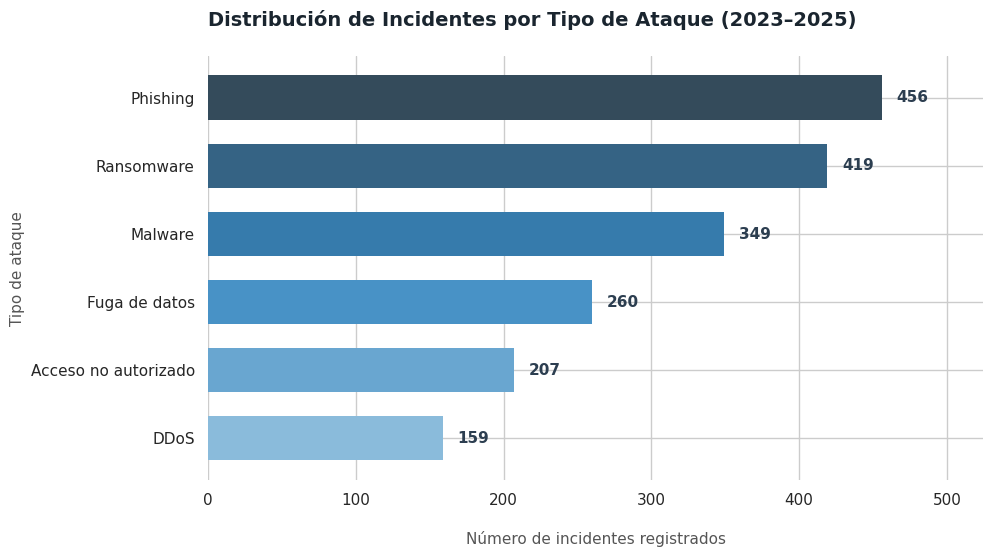

In [ ]:
sns.set_theme(style="whitegrid")
conteo_ataques = limpio["tipo_ataque"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))

colores = sns.color_palette("Blues_d", len(conteo_ataques))
barras = ax.barh(
    conteo_ataques.index,
    conteo_ataques.values,
    color=colores,
    edgecolor="none",
    height=0.65
)
for barra in barras:
    ancho_barra = barra.get_width()
    ax.text(
        ancho_barra + 10,
        barra.get_y() + barra.get_height()/2,
        f'{int(ancho_barra):,}',
        va='center',
        ha='left',
        fontsize=11,
        fontweight='bold',
        color='#2c3e50'
    )
ax.set_title("Distribución de Incidentes por Tipo de Ataque (2023–2025)\n", fontsize=14, fontweight='bold', color='#1a252f', loc='left')
ax.set_xlabel("\nNúmero de incidentes registrados", fontsize=11, color='#555555')
ax.set_ylabel("Tipo de ataque", fontsize=11, color='#555555')

sns.despine(left=True, bottom=True)

ax.set_xlim(0, max(conteo_ataques.values) * 1.15)

fig.savefig("visualizaciones/barras-tipo-ataque-mejorado.png", dpi=300, bbox_inches="tight")
plt.show()

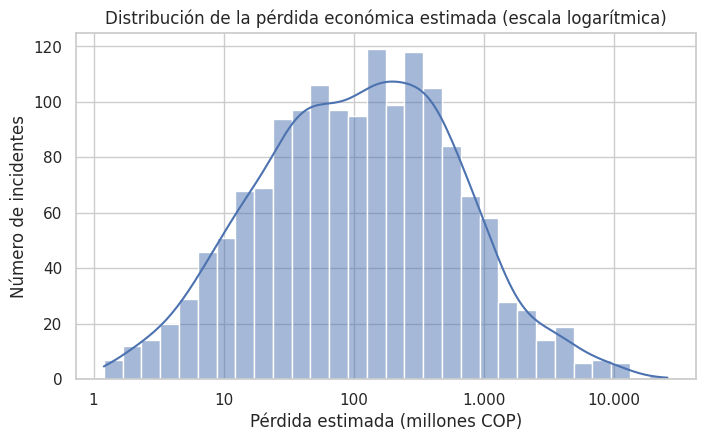

In [ ]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 6.5))

# Crear el histograma con escala logarítmica y un diseño más limpio y moderno
sns.histplot(
    data=obs_perdida,
    x="perdida_estimada_millones_cop",
    bins=30,
    log_scale=True,
    kde=True,
    ax=ax,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.85,
    line_kws={"linewidth": 2.5, "color": "#e74c3c"}
)

# Agregar referencias visuales con líneas horizontales de nivel de frecuencia
# Usamos hlines a diferentes alturas para mostrar el rango típico y el valor exacto
ax.axhline(y=45, color='#c0392b', linestyle='--', linewidth=2, label='Frecuencia Alta (45 Incidentes)')
ax.axhline(y=10, color='#27ae60', linestyle='--', linewidth=2, label='Frecuencia Baja (10 Incidentes)')

# Agregar anotaciones con flechas y números de aclaración para millones de COP
ax.annotate(
    'Mediana Microempresa\n9.1 Millones COP',
    xy=(9.1, 45),
    xytext=(1.2, 55),
    arrowprops=dict(facecolor='#27ae60', shrink=0.08, width=1.5, headwidth=6),
    fontsize=10,
    color='#27ae60',
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="#f4fbf7", ec="#27ae60", lw=0.5)
)

ax.annotate(
    'Mediana Grande Empresa\n597.7 Millones COP',
    xy=(597.7, 45),
    xytext=(2500, 55),
    arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
    fontsize=10,
    color='#c0392b',
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="#fdf5f5", ec="#c0392b", lw=0.5)
)

# Personalizar títulos y etiquetas para mayor claridad
ax.set_title("Distribución de la Pérdida Económica Estimada por Incidente (2023–2025)\n", fontsize=14, fontweight='bold', color='#1a252f', loc='left')
ax.set_xlabel("\nPérdida estimada (Millones de Pesos Colombianos - COP, Escala Logarítmica)", fontsize=11, color='#555555')
ax.set_ylabel("Número de incidentes registrados", fontsize=11, color='#555555')

# Añadir la leyenda para las referencias de aclaración
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Limpiar los bordes del gráfico
sns.despine(left=True, bottom=True)

# Guardar y mostrar la visualización mejorada
fig.savefig("visualizaciones/histograma-perdida-economica.png", dpi=300, bbox_inches="tight")
plt.show()

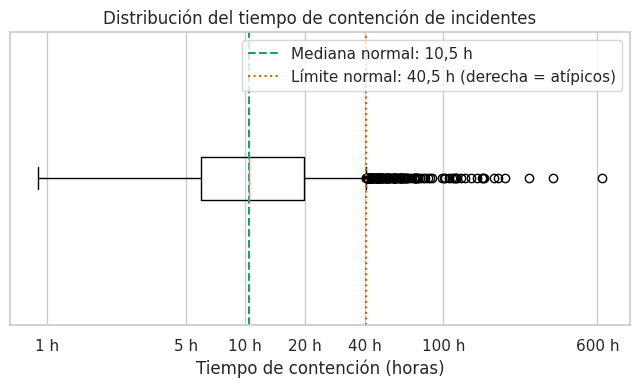

In [ ]:
obs_contencion = limpio.loc[~limpio["contencion_imputada"], "horas_contencion"]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot(obs_contencion, vert=False)

# Ajustar escala para que la caja se vea grande y clara
ax.set_xscale("log")
ax.set_xticks([1, 5, 10, 20, 40, 100, 600])
ax.set_xticklabels(["1 h", "5 h", "10 h", "20 h", "40 h", "100 h", "600 h"])

# Líneas de guía visuales
ax.axvline(10.45, color="#1b9e77", linestyle="--", linewidth=1.5, label="Mediana normal: 10,5 h")
ax.axvline(40.5, color="#d95f02", linestyle=":", linewidth=1.5, label="Límite normal: 40,5 h (derecha = atípicos)")

ax.set_title("Distribución del tiempo de contención de incidentes")
ax.set_xlabel("Tiempo de contención (horas)")
ax.set_yticks([])
ax.legend(loc="upper right")

fig.savefig("visualizaciones/boxplot-horas-contencion.png", dpi=150, bbox_inches="tight")
plt.show()

B. Cuatro Gráficas Multivariadas


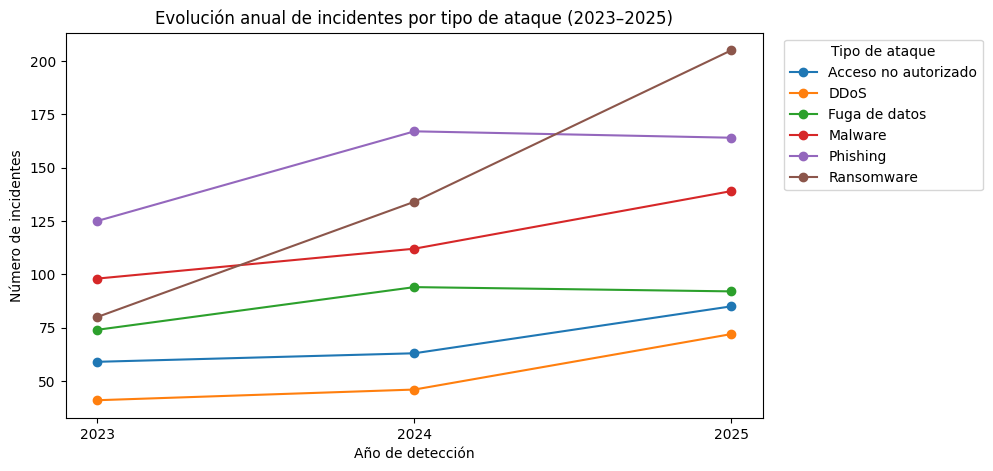

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
for ataque in p1_evolucion.columns:
    ax.plot(p1_evolucion.index, p1_evolucion[ataque], marker="o", label=ataque)
ax.set_title("Evolución anual de incidentes por tipo de ataque (2023–2025)")
ax.set_xlabel("Año de detección")
ax.set_ylabel("Número de incidentes")
ax.set_xticks([2023, 2024, 2025])
ax.legend(title="Tipo de ataque", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.savefig("visualizaciones/evolucion-anual-tipo-ataque.png", dpi=150, bbox_inches="tight")
plt.show()


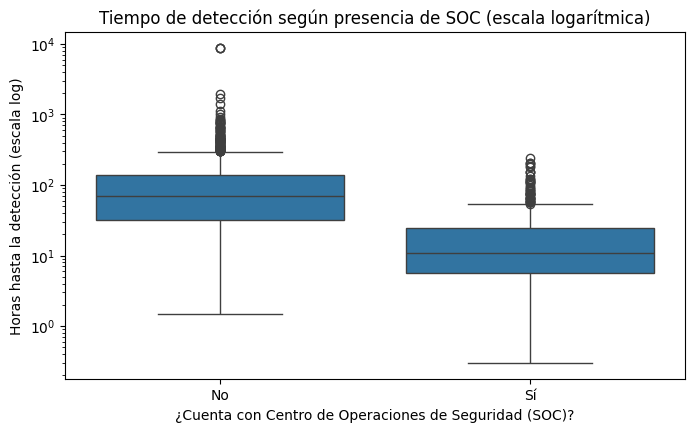

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=limpio, x="tiene_soc", y="horas_deteccion", order=["No", "Sí"], ax=ax)
ax.set_yscale("log")
ax.set_title("Tiempo de detección según presencia de SOC (escala logarítmica)")
ax.set_xlabel("¿Cuenta con Centro de Operaciones de Seguridad (SOC)?")
ax.set_ylabel("Horas hasta la detección (escala log)")
fig.savefig("visualizaciones/boxplot-deteccion-por-soc.png", dpi=150, bbox_inches="tight")
plt.show()


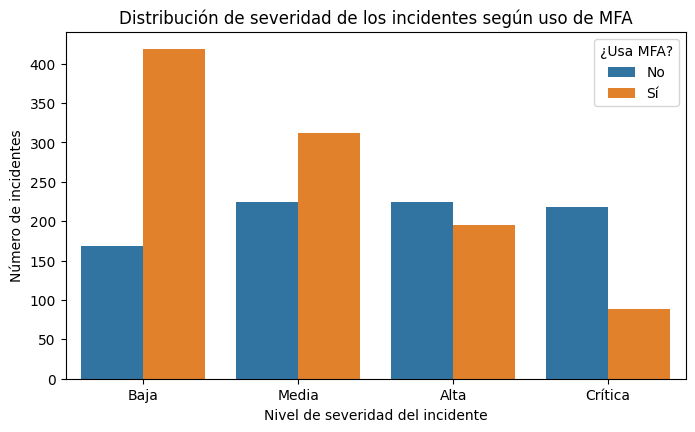

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=limpio, x="severidad", hue="tiene_mfa", order=["Baja", "Media", "Alta", "Crítica"], hue_order=["No", "Sí"], ax=ax)
ax.set_title("Distribución de severidad de los incidentes según uso de MFA")
ax.set_xlabel("Nivel de severidad del incidente")
ax.set_ylabel("Número de incidentes")
ax.legend(title="¿Usa MFA?")
fig.savefig("visualizaciones/barras-severidad-por-mfa.png", dpi=150, bbox_inches="tight")
plt.show()


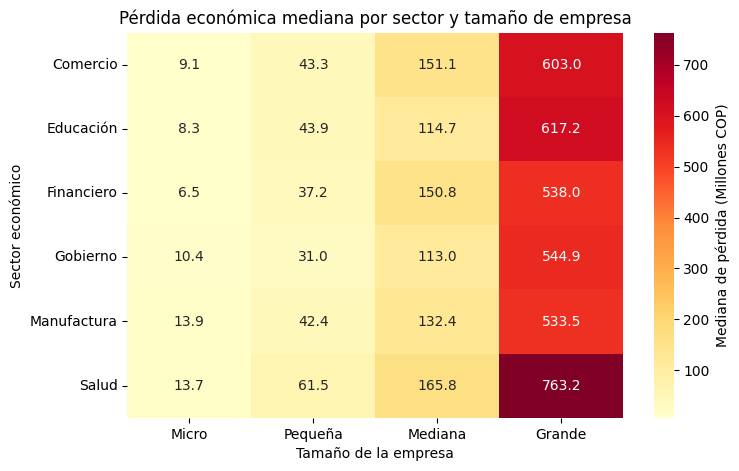

In [ ]:
tabla_calor = obs_perdida.pivot_table(
    values="perdida_estimada_millones_cop",
    index="sector",
    columns="tamano_empresa",
    aggfunc="median"
)[["Micro", "Pequeña", "Mediana", "Grande"]]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(tabla_calor, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Mediana de pérdida (Millones COP)"}, ax=ax)
ax.set_title("Pérdida económica mediana por sector y tamaño de empresa")
ax.set_xlabel("Tamaño de la empresa")
ax.set_ylabel("Sector económico")
fig.savefig("visualizaciones/heatmap-perdida-sector-tamano.png", dpi=150, bbox_inches="tight")
plt.show()
